# 01 · El borde levantado: cómo sabemos que un hoyo es un cráter

Respalda las **dos primeras páginas** de `guia_exposicion_modelo.pdf` (las dos figuras) y las preguntas *«¿Qué tiene de distinto su
proyecto?»*, *«¿Su puntaje pone un análogo real por encima de un hoyo cualquiera?»*, *«¿Qué tiene que ver el borde con los
análogos?»*, *«¿Los cráteres de la Luna tienen ese borde en sus datos?»* y *«¿Y las minas?»*.

**La idea.** Un impacto o una explosión volcánica apilan material alrededor del hoyo: el terreno pegado al cráter queda más alto
que el terreno lejano, como un labio. Un valle cerrado, una presa, una hondonada entre dunas o un tajo minero no lo tienen.

**Qué hace este cuaderno.** Mide ese labio con los perfiles de relieve que ya están en el repo (no descarga nada) y comprueba si
separa los cráteres que ya conocemos de lo demás. La medida es la de `model/borde.py`; las cifras deben coincidir con
`model/VALIDATION.md`, y la última celda lo comprueba.

**Para reproducir las cifras exactas** hay que abrirlo con las versiones fijadas (ver `README.md` de esta carpeta).

In [1]:
# Preparación: encuentra la raíz del repo (local o Colab) para poder usar el código de model/
import subprocess, sys
from pathlib import Path
REPO, PISTA = "Niettzche/spaceapps-2026", "ciencia_datos/datos/perfiles_radiales.json"
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / PISTA).exists()), None)
if RAIZ is None:      # Colab: el repo es privado, así que clona con el token guardado en el secreto GITHUB_TOKEN
    try:
        from google.colab import userdata
        url = f"https://{userdata.get('GITHUB_TOKEN')}@github.com/{REPO}.git"
    except Exception:
        url = f"https://github.com/{REPO}.git"
    subprocess.run(["git", "clone", "--depth", "1", url, "/content/spaceapps-2026"], check=True)
    RAIZ = Path("/content/spaceapps-2026")
sys.path.insert(0, str(RAIZ))

import json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sklearn
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 220)
VALIDACION = (RAIZ / "model" / "VALIDATION.md").read_text(encoding="utf-8")
print(f"repo: {RAIZ.name} · numpy {np.__version__} · pandas {pd.__version__} · scikit-learn {sklearn.__version__}")
from model import borde

repo: spaceapps-2026 · numpy 2.1.3 · pandas 2.2.3 · scikit-learn 1.5.2


In [2]:
# Estilo de las figuras: líneas delgadas, rejilla discreta, texto en tinta (no en el color de la serie)
AZUL, NARANJA, VERDE, TINTA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#1d2024", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#b9b6ae", "axes.labelcolor": GRIS, "xtick.color": GRIS, "ytick.color": GRIS,
                     "axes.grid": True, "grid.color": "#e4e2dc", "grid.linewidth": 0.8, "legend.frameon": False})

## 1. Qué es un perfil radial

Para cada candidato, `analisis/18_perfiles_radiales.py` promedió la altura del terreno en 12 anillos alrededor del centro, de 0 a
2 radios, con el relieve de Copernicus llevado a 80 m. La altura va **relativa al terreno lejano** (los anillos de afuera) y
**dividida entre el diámetro**, para comparar forma y no tamaño. Aquí la mostramos en metros por kilómetro de diámetro.

In [3]:
r, sitios = borde.perfiles()
a, b, lejos = borde.limites_ventana()
print(f"{len(sitios)} candidatos con perfil · {len(r)} anillos, con centro en {r[0]:.2f} … {r[-1]:.2f} radios")
print(f"zona del borde (lo que medimos): de {a:.2f} a {b:.2f} radios · terreno lejano (la referencia, cero): de {lejos:.2f} a 2 radios")

298 candidatos con perfil · 12 anillos, con centro en 0.08 … 1.92 radios
zona del borde (lo que medimos): de 0.83 a 1.67 radios · terreno lejano (la referencia, cero): de 1.67 a 2 radios


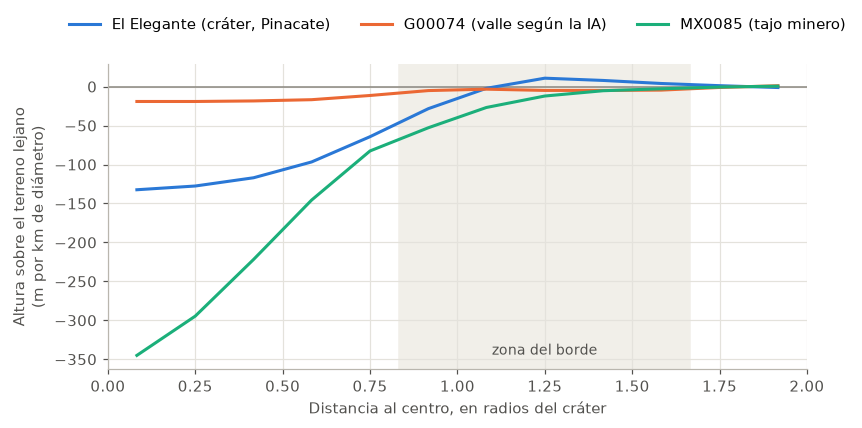

En el cráter, la línea cruza el cero y sube antes de volver al nivel del terreno lejano. En el valle y en el tajo, no.


In [4]:
t = borde.tabla_candidatos()          # los candidatos áridos con ficha, su h/D y, si la hay, la fuente que dice que son un cráter
t["levantado"] = t.h > borde.UMBRAL
con_fuente = t.con_fuente.notna()
alta = t.conf_ia >= 0.7
crater_ia = alta & t.etiqueta_ia.isin(["crater_volcanico", "crater_impacto"])
valle = alta & t.etiqueta_ia.isin(["presa_o_lago", "valle_o_canada", "hondonada_eolica_o_duna"])
tajo = (t.km_mina <= 2.0) & ~con_fuente
P = np.array([sitios[i]["tierra"] for i in t.id], float) * 1000       # metros por km de diámetro

# Tres ejemplos: un cráter conocido, el valle con la etiqueta más segura y un tajo con cantera de OpenStreetMap
ej_valle = t[valle].sort_values("conf_ia", ascending=False).id.iloc[0]
ejemplos = [("MX0008", "El Elegante (cráter, Pinacate)", AZUL), (ej_valle, f"{ej_valle} (valle según la IA)", NARANJA),
            ("MX0085", "MX0085 (tajo minero)", VERDE)]
fig, ax = plt.subplots(figsize=(8.2, 3.6))
ax.axvspan(a, b, color="#f1efe9", zorder=0); ax.axhline(0, color="#8a8780", lw=1)
for cid, nombre, color in ejemplos:
    ax.plot(r, P[(t.id == cid).to_numpy()][0], color=color, lw=2, label=nombre)
ax.set(xlabel="Distancia al centro, en radios del cráter", ylabel="Altura sobre el terreno lejano\n(m por km de diámetro)", xlim=(0, 2))
ax.text((a + b) / 2, ax.get_ylim()[0] * 0.96, "zona del borde", ha="center", va="bottom", color=GRIS, fontsize=9)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.2), ncol=3)        # arriba, para no tapar la etiqueta de la zona
plt.show()
print("En el cráter, la línea cruza el cero y sube antes de volver al nivel del terreno lejano. En el valle y en el tajo, no.")

## 2. La medida

`h/D` = la altura **máxima** del perfil dentro de la zona del borde, sobre el terreno lejano, dividida entre el diámetro.
Hay **borde levantado** si `h/D` > 0. Es una sola línea de código (`borde.altura`).

In [5]:
for cid, nombre, _ in ejemplos:
    h = borde.medir(cid)
    d = float(t.loc[t.id == cid, "diam_km"].iloc[0])
    print(f"{nombre:34s} h/D = {h:+.4f}  →  {h * d * 1000:+6.1f} m  →  borde levantado: {'sí' if borde.levantado(h) else 'no'}")

El Elegante (cráter, Pinacate)     h/D = +0.0108  →   +15.6 m  →  borde levantado: sí
G00074 (valle según la IA)         h/D = -0.0033  →   -16.6 m  →  borde levantado: no
MX0085 (tajo minero)               h/D = -0.0028  →    -2.3 m  →  borde levantado: no


## 3. ¿Lo tienen los cráteres que ya conocemos?

Tres grupos, definidos igual que en `model/validate.py`:

- **Cráteres con fuente externa:** identificados por el catálogo de cráteres volcánicos de México, la lista de cráteres de impacto
  o la literatura. La etiqueta de IA **no** interviene.
- **Valles, presas y dunas:** según la etiqueta de IA con confianza de 0.7 o más.
- **Tajos mineros:** con una cantera de OpenStreetMap a 2 km o menos. Tampoco interviene la IA.

Al final van los cráteres de referencia de la Luna y de Marte (los «gemelos» de cada candidato), medidos igual.

In [6]:
ref = {c: pd.Series([borde.altura(list(p), r) for p in borde.perfiles_referencia(c)]) > borde.UMBRAL for c in ("luna", "marte")}
grupos = {"Cráteres con fuente externa": t.levantado[con_fuente], "Cráter natural según la IA (≥ 0.7)": t.levantado[crater_ia],
          "Valles, presas y dunas según la IA (≥ 0.7)": t.levantado[valle], "Tajos con cantera de OpenStreetMap": t.levantado[tajo],
          "Todos los candidatos áridos": t.levantado, "Referencia: gemelos lunares (LOLA, 80 m)": ref["luna"],
          "Referencia: gemelos marcianos (HRSC+MOLA, 200 m)": ref["marte"]}
resumen = pd.DataFrame([{"grupo": g, "casos": len(m), "con borde levantado": int(m.sum()), "%": round(100 * m.mean())} for g, m in grupos.items()])
resumen

,grupo,casos,con borde levantado,%
0,Cráteres con fuente externa,11,10,91
1,Cráter natural según la IA (≥ 0.7),14,13,93
2,"Valles, presas y dunas según la IA (≥ 0.7)",26,3,12
3,Tajos con cantera de OpenStreetMap,38,4,11
4,Todos los candidatos áridos,296,57,19
5,"Referencia: gemelos lunares (LOLA, 80 m)",248,55,22
6,"Referencia: gemelos marcianos (HRSC+MOLA, 200 m)",59,9,15


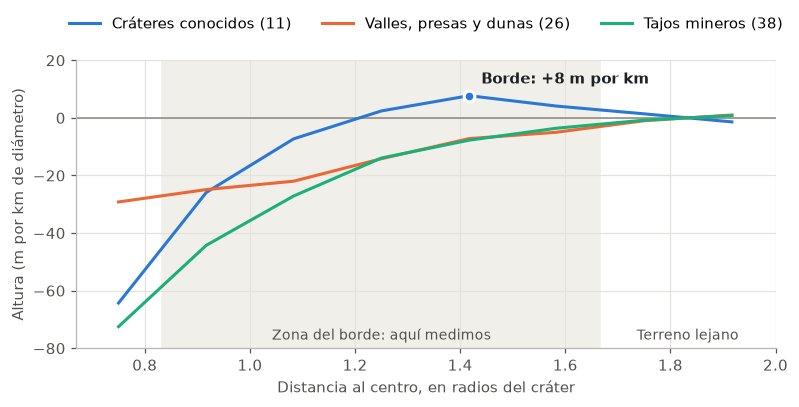

In [7]:
# La figura de la página 1 del PDF: perfil mediano de cada grupo, solo cerca del borde
series = [("Cráteres conocidos", con_fuente, AZUL), ("Valles, presas y dunas", valle, NARANJA), ("Tajos mineros", tajo, VERDE)]
ver = r >= 0.7
fig, ax = plt.subplots(figsize=(8.2, 3.4))
ax.axvspan(a, b, color="#f1efe9", zorder=0); ax.axhline(0, color="#8a8780", lw=1)
for nombre, m, color in series:
    ax.plot(r[ver], np.median(P[m.to_numpy()], axis=0)[ver], color=color, lw=2, label=f"{nombre} ({int(m.sum())})")
med = np.median(P[con_fuente.to_numpy()], axis=0)
k = int(np.argmax(np.where(ver, med, -np.inf)))
ax.plot(r[k], med[k], "o", color=AZUL, ms=7, mec="white", mew=2)
ax.annotate(f"Borde: +{med[k]:.0f} m por km", (r[k], med[k]), xytext=(8, 8), textcoords="offset points", color=TINTA, fontweight="bold")
ax.set(xlabel="Distancia al centro, en radios del cráter", ylabel="Altura (m por km de diámetro)", xlim=(0.67, 2.0), ylim=(-80, 20))
ax.text((a + b) / 2, -77, "Zona del borde: aquí medimos", ha="center", color=GRIS, fontsize=9)
ax.text((b + 2) / 2, -77, "Terreno lejano", ha="center", color=GRIS, fontsize=9)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.2), ncol=3)
plt.show()

## 4. Uno por uno: los 11 cráteres con fuente

`puesto por borde` es el lugar que ocupa entre todos los candidatos al ordenarlos por `h/D`; `puesto por forma`, al ordenarlos
por el puntaje de forma del modelo (`model/forma.py`). Si el borde sirve, los cráteres conocidos deben quedar arriba.

In [8]:
from model import forma
pf = forma.puntuar(t.diam_km, t.prof_m, t.borde_m)
t["forma_mejor"] = np.maximum(pf.forma_polo_sur_lunar, pf.forma_jezero).values
t["puesto por borde"] = t.h.rank(ascending=False, method="min").astype(int)
t["puesto por forma"] = t.forma_mejor.rank(ascending=False, method="min").astype(int)
cf = t[con_fuente].sort_values("puesto por borde")
uno = pd.DataFrame({"id": cf.id, "de dónde se sabe que es un cráter": cf.con_fuente, "h/D": cf.h.round(4),
                    "borde (m)": (cf.h * cf.diam_km * 1000).round(1), "levantado": np.where(cf.levantado, "sí", "no"),
                    "puesto por borde": cf["puesto por borde"], "puesto por forma": cf["puesto por forma"]}).reset_index(drop=True)
print(f"Entre los 20 primeros de {len(t)}:  por borde {int((cf['puesto por borde'] <= 20).sum())} de {len(cf)}  ·  por forma {int((cf['puesto por forma'] <= 20).sum())} de {len(cf)}")
uno

Entre los 20 primeros de 296:  por borde 7 de 11  ·  por forma 2 de 11


,id,de dónde se sabe que es un cráter,h/D,borde (m),levantado,puesto por borde,puesto por forma
0,G00266,"cono de toba Jabal Bayda, a ~0.04 km (OpenStreetMap; NASA Earth Observatory ...",0.0369,38.2,sí,2,67
1,G00195,"Meteor Crater, a 0.04 km (lista de cráteres de impacto, ciencia_datos/datos/...",0.0217,23.5,sí,4,18
2,G00263,"maar Al Hutaymah, a ~0.10 km (OpenStreetMap; USGS OFR 85-125)",0.0140,18.1,sí,7,69
3,MX0261,"Hoya Rincón de Parangueo, a 0.20 km (catálogo de cráteres de México)",0.0118,16.2,sí,11,143
4,MX0008,"Cráter El Elegante, a 0.21 km (catálogo de cráteres de México)",0.0108,15.6,sí,12,10
5,MX0010,"Sykes (Cráter Grande / Volcán Romo), a 0.34 km (catálogo de cráteres de México)",0.0107,9.7,sí,13,207
6,MX0009,"Celaya (Volcán Los Vidrios), a 0.01 km (catálogo de cráteres de México)",0.0059,5.8,sí,20,256
7,MX0012,"Cerro Colorado, a 0.33 km (catálogo de cráteres de México)",0.0041,2.6,sí,23,245
8,G00281,"maar Al Wahbah, a ~0.23 km (IUGS Geoheritage)",0.0028,6.1,sí,29,182
9,MX0007,"MacDougal (Cráter Verdugo), a 0.35 km (catálogo de cráteres de México)",0.0021,3.4,sí,35,215


In [9]:
# ¿Qué hay entre los 25 primeros con cada criterio? (según la etiqueta de IA, con cualquier confianza)
def primeros(col):
    e = t.loc[t[col] <= 25, "etiqueta_ia"]
    return {"cráteres naturales": int(e.isin(["crater_volcanico", "crater_impacto"]).sum()), "minas": int((e == "mina_o_cantera").sum()),
            "otros": int((~e.isin(["crater_volcanico", "crater_impacto", "mina_o_cantera"])).sum())}
pd.DataFrame({"25 primeros por borde": primeros("puesto por borde"), "25 primeros por forma": primeros("puesto por forma")})

,25 primeros por borde,25 primeros por forma
cráteres naturales,11,3
minas,1,14
otros,13,8


## 5. ¿Qué tan bien separa?

El **AUC** es la probabilidad de que un cráter tomado al azar tenga más borde que un no-cráter tomado al azar: 0.5 es no separar
nada y 1 es separar perfecto. La `p` sale de una prueba de permutación (5,000 barajadas): qué tan seguido el azar da algo así.

In [10]:
from model.validate import auc, p_permutacion
filas = []
for nombre, pos, neg in [("cráter natural contra valle, presa o duna (los dos según la IA, ≥ 0.7)", crater_ia, valle),
                         ("cráteres con fuente contra tajos de OpenStreetMap (sin IA en ningún lado)", con_fuente, tajo)]:
    filas.append({"comparación": nombre, "casos": f"{int(pos.sum())} contra {int(neg.sum())}",
                  "AUC del borde": round(auc(t.h[pos], t.h[neg]), 2), "p del borde": round(p_permutacion(t.h[pos], t.h[neg]), 4),
                  "AUC del puntaje de forma": round(auc(t.forma_mejor[pos], t.forma_mejor[neg]), 2)})
pd.DataFrame(filas)

,comparación,casos,AUC del borde,p del borde,AUC del puntaje de forma
0,"cráter natural contra valle, presa o duna (los dos según la IA, ≥ 0.7)",14 contra 26,0.91,0.0002,0.42
1,cráteres con fuente contra tajos de OpenStreetMap (sin IA en ningún lado),11 contra 38,0.91,0.0002,0.36


## 6. ¿Cráter o mina? El corte que el puntaje de forma no ve

Es la figura de «Lo que nos distingue» en la guía. Los dos ejemplos **no se eligieron a ojo**: son el cráter con fuente externa y
el tajo (etiqueta de IA «mina o cantera» con confianza de 0.7 o más) que quedan **mejor puestos por el puntaje de forma**.

In [11]:
mina_ia = (t.etiqueta_ia == "mina_o_cantera") & (t.conf_ia >= 0.7)
ej_c = t[con_fuente].sort_values("puesto por forma").iloc[0]
ej_m = t[mina_ia].sort_values("puesto por forma").iloc[0]
como = {ej_c.id: ej_c.con_fuente,
        ej_m.id: f"etiqueta de IA mina_o_cantera (confianza {ej_m.conf_ia:.2f}); cantera de OpenStreetMap a {ej_m.km_mina:.1f} km"}
for cid, texto in como.items():
    print(f"{cid}: {texto}")
pd.DataFrame([{"id": f.id, "diámetro (km)": round(f.diam_km, 2),
               "profundidad / diámetro": round(f.prof_diam, 3), "puntaje de forma": round(f.forma_mejor, 3),
               "puesto por forma": f["puesto por forma"], "h/D del borde": round(f.h, 4), "puesto por borde": f["puesto por borde"],
               "borde levantado": "sí" if f.levantado else "no"} for f in (ej_c, ej_m)]).set_index("id").T

MX0008: Cráter El Elegante, a 0.21 km (catálogo de cráteres de México)
G00219: etiqueta de IA mina_o_cantera (confianza 0.93); cantera de OpenStreetMap a 1.9 km


id,MX0008,G00219
diámetro (km),1.44,0.75
profundidad / diámetro,0.139,0.159
puntaje de forma,0.972,0.991
puesto por forma,10,3
h/D del borde,0.0108,-0.0058
puesto por borde,12,183
borde levantado,sí,no


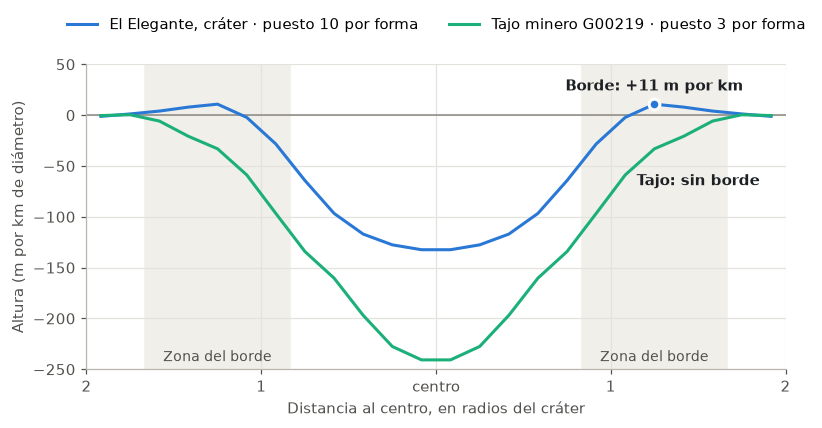

En la zona del borde, el cráter llega a +10.8 m por km de diámetro; el tajo no pasa de -5.8.
Gemelo de El Elegante en luna: h/D = -0.0211 → borde levantado: no
Gemelo de El Elegante en marte: h/D = +0.0111 → borde levantado: sí


In [12]:
pc, pm = (P[(t.id == f.id).to_numpy()][0] for f in (ej_c, ej_m))
xs = np.concatenate([-r[::-1], r])                      # el perfil es un promedio por anillos: se dibuja a los dos lados del centro
nombre_c = ej_c.id if pd.isna(ej_c.nombre) else ej_c.nombre.split(" (")[0]
fig, ax = plt.subplots(figsize=(8.2, 3.6))
for lo, hi in ((a, b), (-b, -a)):
    ax.axvspan(lo, hi, color="#f1efe9", zorder=0)
ax.axhline(0, color="#8a8780", lw=1)
ax.plot(xs, np.concatenate([pc[::-1], pc]), color=AZUL, lw=2, label=f"{nombre_c}, cráter · puesto {ej_c['puesto por forma']} por forma")
ax.plot(xs, np.concatenate([pm[::-1], pm]), color=VERDE, lw=2, label=f"Tajo minero {ej_m.id} · puesto {ej_m['puesto por forma']} por forma")
k = int(np.argmax(np.where((r >= borde.VENTANA[0]) & (r < borde.VENTANA[1]), pc, -np.inf)))
ax.plot(r[k], pc[k], "o", color=AZUL, ms=7, mec="white", mew=2)
ax.annotate(f"Borde: +{pc[k]:.0f} m por km", (r[k], pc[k]), xytext=(0, 9), textcoords="offset points", ha="center", color=TINTA, fontweight="bold")
ax.annotate("Tajo: sin borde", (1.5, pm[int(np.argmin(np.abs(r - 1.42)))]), xytext=(0, -32), textcoords="offset points", ha="center",
            color=TINTA, fontweight="bold")
ax.set(xlabel="Distancia al centro, en radios del cráter", ylabel="Altura (m por km de diámetro)", xlim=(-2, 2), ylim=(50 * np.floor(pm.min() / 50), 50))
ax.set_xticks([-2, -1, 0, 1, 2], ["2", "1", "centro", "1", "2"])
for x in (-(a + b) / 2, (a + b) / 2):
    ax.text(x, ax.get_ylim()[0] + 8, "Zona del borde", ha="center", color=GRIS, fontsize=9)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.2), ncol=2)
plt.show()
print(f"En la zona del borde, el cráter llega a {pc[k]:+.1f} m por km de diámetro; el tajo no pasa de {pm[(r >= borde.VENTANA[0]) & (r < borde.VENTANA[1])].max():+.1f}.")
for cuerpo in ("luna", "marte"):                        # lo mismo, medido en los gemelos del cráter en la Luna y en Marte
    h = borde.medir(ej_c.id, cuerpo)
    print(f"Gemelo de {nombre_c} en {cuerpo}: " + ("sin perfil" if h is None else f"h/D = {h:+.4f} → borde levantado: {'sí' if borde.levantado(h) else 'no'}"))

**Cómo leerla.** Para el puntaje de forma los dos quedan arriba, y el tajo más arriba que el cráter: los dos son hoyos hondos
para su tamaño. El corte muestra lo que ese puntaje no ve: el cráter sube por encima del terreno lejano antes de bajar; el tajo no.

**Con cuidado.**
- Es **un ejemplo**. La cuenta completa está en la sección 4 (qué hay entre los 25 primeros) y en la 5 (AUC).
- No es un corte del terreno en una dirección: es el **promedio por anillos**, dibujado a los dos lados para que se lea como corte.
- El gemelo lunar de este cráter **no** muestra borde con la misma medida. El borde dice «es un cráter», no «se parece a la Luna».

## 7. Sensibilidad: ¿y si la zona del borde fuera otra?

**Ojo, hay que decirlo:** la zona ancha (la que usamos) se eligió **después** de ver que la estrecha dejaba fuera a cráteres con
fuente. Con tan pocos casos, eso es ajustar a la muestra. Por eso se muestran todas las combinaciones.

In [13]:
filas = []
for ventana in ((0.9, 1.3), (0.75, 1.6), borde.VENTANA):
    va, vb, _ = borde.limites_ventana(ventana)
    h = pd.Series([borde.medir(i, ventana=ventana) for i in t.id], dtype=float)
    for u in (0.0, 0.002):
        m = h > u
        filas.append({"zona (radios)": f"{va:.2f}–{vb:.2f}" + ("  ← la usada" if ventana == borde.VENTANA and u == borde.UMBRAL else ""),
                      "umbral h/D": u, "cráteres con fuente": f"{int(m[con_fuente].sum())} de {int(con_fuente.sum())}",
                      "valles, presas, dunas": f"{int(m[valle].sum())} de {int(valle.sum())}",
                      "tajos": f"{int(m[tajo].sum())} de {int(tajo.sum())}", "todos": f"{int(m.sum())} de {len(m)}"})
pd.DataFrame(filas)

,zona (radios),umbral h/D,cráteres con fuente,"valles, presas, dunas",tajos,todos
0,0.83–1.33,0.000,7 de 11,1 de 26,0 de 38,23 de 296
1,0.83–1.33,0.002,7 de 11,1 de 26,0 de 38,17 de 296
2,0.67–1.67,0.000,10 de 11,3 de 26,4 de 38,57 de 296
3,0.67–1.67,0.002,10 de 11,2 de 26,4 de 38,36 de 296
4,0.83–1.67 ← la usada,0.000,10 de 11,3 de 26,4 de 38,57 de 296
5,0.83–1.67,0.002,10 de 11,2 de 26,4 de 38,36 de 296


## 8. Qué pasa en nuestro catálogo (`data/sites`)

La medida está guardada en cada sitio como `variables.borde_levantado` (en metros). La categoría (cráter natural, tajo, sin
verificar) es la de `model/scan.py`, regla 6.

In [14]:
from model import scan
etiquetas, filas = scan.etiquetas_ia(), []
for f in sorted((RAIZ / "data" / "sites").glob("*.json")):
    s = json.loads(f.read_text(encoding="utf-8"))
    cid = borde.crater_de(s)
    if cid is None:
        continue                                    # sin cráter medido (las dunas de Samalayuca)
    cat = scan.categoria(s, etiquetas)[0] if s["estado"] == "candidato_modelo" else "curado"
    filas.append({"id": s["id"], "nombre": s["nombre"][:44], "categoría": cat, "novedoso": s.get("novedoso"),
                  "borde (m)": s["variables"]["borde_levantado"]["valor"], "levantado": borde.levantado(borde.medir(cid))})
cat = pd.DataFrame(filas)
print(cat.groupby("categoría").agg(sitios=("id", "size"), con_borde=("levantado", lambda x: int(x.fillna(False).sum()))).to_string())
print(f"\nTajos con novedoso = true: {int(((cat.categoría == 'tajo_minero') & (cat.novedoso == True)).sum())}; "
      f"de ellos, con borde levantado: {int(((cat.categoría == 'tajo_minero') & (cat.novedoso == True) & (cat.levantado == True)).sum())}")
cat[cat.levantado == True].sort_values("borde (m)", ascending=False).reset_index(drop=True)

                sitios  con_borde
categoría                        
crater_natural       5          4
curado               1          1
sin_verificar       29          5
tajo_minero         22          0

Tajos con novedoso = true: 17; de ellos, con borde levantado: 0


,id,nombre,categoría,novedoso,borde (m),levantado
0,g00266,"Cono de toba Jabal Bayda (Harrat Khaybar, Ar",crater_natural,None,38.2,True
1,g00263,"Maar Al Hutaymah (Harrat Hutaymah, Arabia Sa",crater_natural,None,18.1,True
2,mx0261,Hoya Rincón de Parangueo,crater_natural,False,16.2,True
3,pinacate,Campo volcánico El Pinacate,curado,False,15.6,True
4,mx0045,Depresión tipo cráter MX0045,sin_verificar,None,14.3,True
5,mx0121,Depresión tipo cráter MX0121,sin_verificar,None,7.9,True
6,mx0017,Depresión tipo cráter MX0017,sin_verificar,None,7.0,True
7,g00281,"Maar Al Wahbah (Harrat Kishb, Arabia Saudita",crater_natural,None,6.1,True
8,mx0047,Depresión tipo cráter MX0047,sin_verificar,None,4.7,True
9,mx0003,Depresión tipo cráter MX0003,sin_verificar,False,1.3,True


## 9. Prueba fuera de muestra: cráteres de impacto que la regla no había visto

La zona del borde y el umbral se fijaron con los candidatos de México, Atacama, Arizona y Arabia (secciones 3 a 7). Aquí se
aplican, **sin cambiar nada**, a cráteres de impacto de otros países. Sus perfiles los sacó `analisis/25_perfiles_impactos.py`
con el mismo método (antes de medir comprueba que reproduce, idénticos, perfiles ya guardados). El centro y el diámetro son los
del detector, igual que en los candidatos. Meteor Crater ya estaba entre los candidatos, así que no cuenta como nuevo.

In [15]:
ti = borde.tabla_impactos()
ti["levantado"] = ti.h > borde.UMBRAL
nuevos = ti[~ti.visto]
h_estrecha = pd.Series([borde.altura(p, None, (0.9, 1.3)) for p in nuevos.perfil], index=nuevos.index)
print(f"Cráteres de impacto que la regla no había visto: {len(nuevos)}  ·  con borde levantado: {int(nuevos.levantado.sum())}")
print(f"Con la zona estrecha: {int((h_estrecha > 0).sum())}  ·  con la usada y umbral 0.002: {int((nuevos.h > 0.002).sum())}")
print("Pasan solo con la zona ancha:", ", ".join(nuevos.nombre[nuevos.levantado & ~(h_estrecha > 0)]) or "ninguno")
pd.DataFrame({"cráter de impacto": ti.nombre, "diámetro del detector (km)": ti.diam_km.round(2), "diámetro esperado (km)": ti.diam_esperado_km,
              "h/D": ti.h.round(4), "borde (m)": (ti.h * ti.diam_km * 1000).round(1), "levantado": np.where(ti.levantado, "sí", "no"),
              "¿nuevo para la regla?": np.where(ti.visto, "no (ya era " + ti.candidato.fillna("") + ")", "sí")})

Cráteres de impacto que la regla no había visto: 8  ·  con borde levantado: 7
Con la zona estrecha: 5  ·  con la usada y umbral 0.002: 6
Pasan solo con la zona ancha: Lonar, Talemzane


,cráter de impacto,diámetro del detector (km),diámetro esperado (km),h/D,borde (m),levantado,¿nuevo para la regla?
0,Meteor Crater,1.06,1.20,0.0245,25.9,sí,no (ya era G00195)
1,Lonar,1.81,1.80,0.0031,5.6,sí,sí
2,Wolfe Creek,0.78,0.90,0.0076,5.9,sí,sí
3,Tenoumer,1.63,1.90,0.0176,28.6,sí,sí
4,Pingualuit,3.07,3.40,0.0075,23.0,sí,sí
5,Tswaing,0.90,1.10,0.0094,8.5,sí,sí
6,Roter Kamm,1.82,2.50,0.0101,18.4,sí,sí
7,Talemzane,1.37,1.75,0.0019,2.6,sí,sí
8,Xiuyan,0.81,1.80,-0.0075,-6.1,no,sí


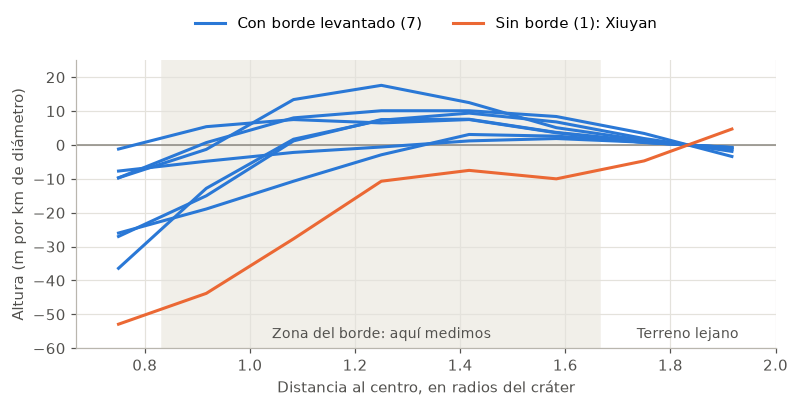

In [16]:
from matplotlib.lines import Line2D
ver = r >= 0.7
fig, ax = plt.subplots(figsize=(8.2, 3.4))
ax.axvspan(a, b, color="#f1efe9", zorder=0); ax.axhline(0, color="#8a8780", lw=1)
for c in nuevos.itertuples():
    ax.plot(r[ver], (np.array(c.perfil) * 1000)[ver], color=AZUL if c.levantado else NARANJA, lw=2)
sin = nuevos[~nuevos.levantado]
ax.legend([Line2D([], [], color=AZUL, lw=2), Line2D([], [], color=NARANJA, lw=2)],
          [f"Con borde levantado ({int(nuevos.levantado.sum())})", f"Sin borde ({len(sin)}): " + (", ".join(sin.nombre) or "ninguno")],
          loc="upper center", bbox_to_anchor=(0.5, 1.2), ncol=2)
ax.set(xlabel="Distancia al centro, en radios del cráter", ylabel="Altura (m por km de diámetro)", xlim=(0.67, 2.0), ylim=(-60, 25))
ax.text((a + b) / 2, -57, "Zona del borde: aquí medimos", ha="center", color=GRIS, fontsize=9)
ax.text((b + 2) / 2, -57, "Terreno lejano", ha="center", color=GRIS, fontsize=9)
plt.show()

**Cómo leerla.** Cada línea es un cráter de impacto que no intervino al fijar la regla. Casi todos cruzan el cero y suben en
la zona del borde, como los cráteres de la sección 3.

**Con cuidado.**
- Son **pocos casos** y **no son una muestra al azar**: son cráteres de impacto conocidos, elegidos antes como control positivo del
  detector (`analisis/15_referencias_extra.py`). Los que el detector no encuentra (Brent, erosionado) no entran, así que esto no
  dice nada de estructuras de impacto erosionadas o sepultadas.
- Algunos pasan **solo con la zona ancha** (los nombra la celda de arriba) y por pocos metros.
- En el que no pasa, el detector midió menos de la mitad del diámetro esperado: el borde real queda probablemente fuera de la
  zona medida, como en Colton.
- Lo que sí responde: la objeción de que la zona del borde se ajustó a la muestra. En estos cráteres no se ajustó nada.

## 10. Lo que hay que decir con cuidado

- **No mide parecido con la Luna ni con Marte.** En la tabla de la sección 3, la mayoría de los cráteres lunares y marcianos de
  referencia no muestra borde con esta medida. No comprobamos por qué; una explicación posible es que son viejos y están encimados.
  El borde responde «¿es un cráter?», no «¿se parece a la Luna?».
- **La muestra es chica:** la regla se fijó con 11 cráteres con fuente, casi todos volcánicos y uno solo de impacto, y se probó
  en los cráteres de impacto de la sección 9.
- **Colton no pasa.** El detector mide ~0.75 km y su fuente da ~1.1 km de borde a borde, así que el borde real probablemente
  cae fuera de la zona medida (`model/NIVEL2.md`, sección A).
- **Las etiquetas de valle, presa y duna vienen de la IA**, que vio el mismo relieve: esa comparación no es independiente. La de
  cráteres con fuente contra canteras de OpenStreetMap sí lo es.
- **El puntaje de similitud no usa el borde.** Va junto a cada sitio, no dentro del número.

In [17]:
# Comprobación: lo que sale aquí es lo mismo que está escrito en model/VALIDATION.md
frac = lambda m: f"{int(m.sum())} de {len(m)} ({m.mean():.0%})"
esperado = [f"| Cráteres con fuente externa (catálogo de México, impactos, literatura) | {frac(t.levantado[con_fuente])} |",
            f"| Presa, valle o duna según la IA, confianza ≥ 0.7 | {frac(t.levantado[valle])} |",
            f"| Tajos con cantera de OpenStreetMap a ≤ 2 km | {frac(t.levantado[tajo])} |",
            f"| Referencia: gemelos lunares (LOLA a 80 m) | {frac(ref['luna'])} |",
            f"| Referencia: gemelos marcianos (HRSC+MOLA a 200 m) | {frac(ref['marte'])} |",
            f"{int((cf['puesto por borde'] <= 20).sum())} de los {len(cf)} cráteres con fuente quedan entre los 20 primeros"]
cuantos = lambda n, uno, varios: f"{n} {uno if n == 1 else varios}"
pb, pfm = primeros("puesto por borde"), primeros("puesto por forma")
esperado.append(f"Entre los 25 primeros por borde hay {cuantos(pb['cráteres naturales'], 'cráter natural', 'cráteres naturales')} según la IA y "
                f"{cuantos(pb['minas'], 'mina', 'minas')}; entre los 25 primeros por forma, "
                f"{cuantos(pfm['cráteres naturales'], 'cráter natural', 'cráteres naturales')} y {cuantos(pfm['minas'], 'mina', 'minas')}.")
esperado.append(f"**De los {len(nuevos)} que la regla no había visto, {int(nuevos.levantado.sum())} tienen borde levantado.**")
for linea in esperado:
    print("✓" if linea in VALIDACION else "✗ NO COINCIDE", linea)
assert all(linea in VALIDACION for linea in esperado), "Este cuaderno y model/VALIDATION.md ya no dicen lo mismo"

✓ | Cráteres con fuente externa (catálogo de México, impactos, literatura) | 10 de 11 (91%) |
✓ | Presa, valle o duna según la IA, confianza ≥ 0.7 | 3 de 26 (12%) |
✓ | Tajos con cantera de OpenStreetMap a ≤ 2 km | 4 de 38 (11%) |
✓ | Referencia: gemelos lunares (LOLA a 80 m) | 55 de 248 (22%) |
✓ | Referencia: gemelos marcianos (HRSC+MOLA a 200 m) | 9 de 59 (15%) |
✓ 7 de los 11 cráteres con fuente quedan entre los 20 primeros
✓ Entre los 25 primeros por borde hay 11 cráteres naturales según la IA y 1 mina; entre los 25 primeros por forma, 3 cráteres naturales y 14 minas.
✓ **De los 8 que la regla no había visto, 7 tienen borde levantado.**
